
# Тест 01: Supervised  learning (Обучение с учителем)

Этот тест предназначен для оценки ваших знаний об импорте данных, их визуализации и использовании моделей машинного обучения.
Пожалуйста, введите ответы непосредственно в ячейки, предназначенные для каждого раздела.


## 1. Импорт данных
    1. Импортируйте библиотеку `pandas` и загрузите файл `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
    2. Проверьте размерности и типы данных.
    3. Выведите первые 5 строк DataFrame и проверьте наличие пропущенных значений.


In [27]:
import pandas as pd
from pathlib import Path

csv_path = Path("Human_Activity_Recognition_Using_Smartphones_Data.csv")
if not csv_path.exists():
    csv_path = Path("att") / csv_path

data = pd.read_csv(csv_path)

feature_columns = [
    "tBodyAcc-mean()-X",
    "tBodyAcc-mean()-Y",
    "tBodyAcc-mean()-Z",
    "tBodyAcc-std()-X",
    "tBodyAcc-std()-Y",
    "tBodyAcc-std()-Z",
]

print("Размер таблицы:", data.shape)
print("Типы данных:")
print(data.dtypes.value_counts())
print("\nПервые пять строк:")
print(data.head())
print("Пропущенных значений:", data.isna().sum().sum())

Размер таблицы: (10299, 562)
Типы данных:
float64    561
str          1
Name: count, dtype: int64

Первые пять строк:
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  \
0         -0.983111         -0.913526         -0.995112         -0.983185   
1         -0.975300         -0.960322         -0.998807         -0.974914   
2         -0.967187         -0.978944         -0.996520         -0.963668   
3         -0.983403         -0.990675         -0.997099         -0.982750   
4         -0.980


## 2. Визуализация данных с помощью Matplotlib и Seaborn
1. Создайте точечную диаграмму (scatter plot) для отображения связи между двумя числовыми столбцами.
2. Используйте Seaborn для создания тепловой карты (heatmap) корреляций между столбцами.

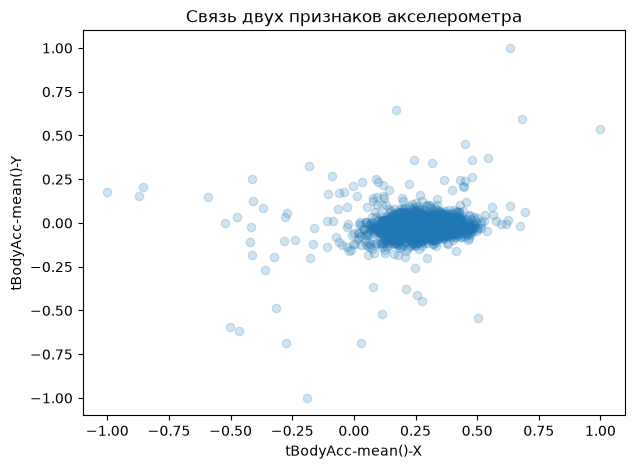

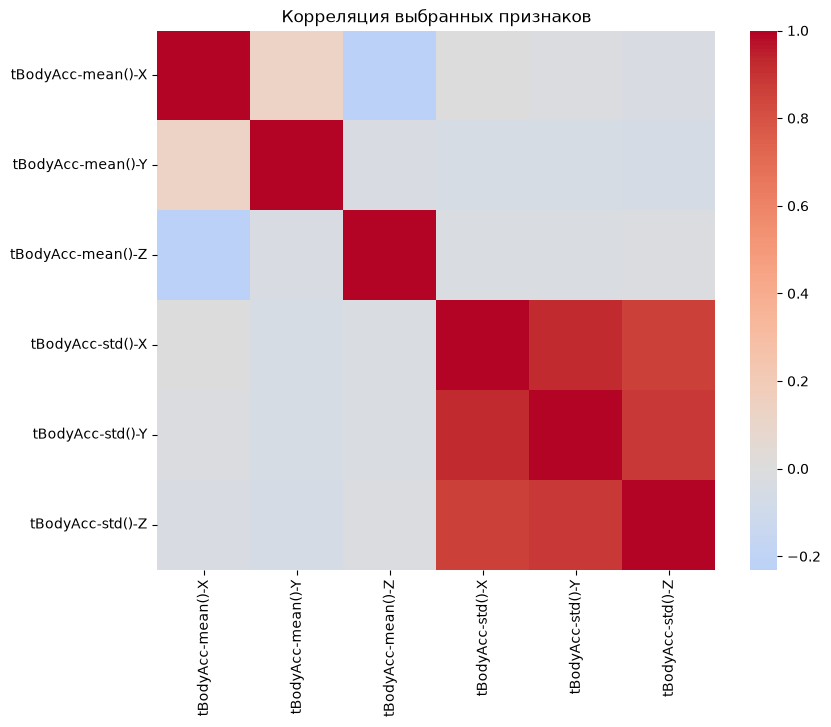

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
plt.scatter(data[feature_columns[0]], data[feature_columns[1]], alpha=0.2)
plt.xlabel(feature_columns[0])
plt.ylabel(feature_columns[1])
plt.title("Связь двух признаков акселерометра")
plt.show()

plt.figure(figsize=(9, 7))
sns.heatmap(data[feature_columns].corr(), cmap="coolwarm", center=0)
plt.title("Корреляция выбранных признаков")
plt.show()

## 3. Метрики ошибки
1. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
2. Постройте модель линейной регрессии на числовых данных.
3. Оцените производительность модели с использованием **MAE**, **MSE** и **RMSE**.

Числовой целевой столбец не задан, поэтому будем предсказывать `angle(X,gravityMean)` по шести признакам акселерометра.

In [29]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

X_regression = data[feature_columns]
y_regression = data["angle(X,gravityMean)"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression, y_regression, test_size=0.2, random_state=42
)

linear_model = LinearRegression()
linear_model.fit(X_reg_train, y_reg_train)
regression_predictions = linear_model.predict(X_reg_test)

mae = mean_absolute_error(y_reg_test, regression_predictions)
mse = mean_squared_error(y_reg_test, regression_predictions)
rmse = np.sqrt(mse)

print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))

MAE: 0.3783
MSE: 0.234
RMSE: 0.4837



## 4. Перекрёстная проверка (Cross Validation)
1. Импортируйте библиотеку `scikit-learn`.
2. Разделите набор данных на обучающую и тестовую выборки (80%-20%).
3. Используйте `cross_val_score` для оценки производительности модели KNN на наборе данных.


In [30]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X = data[feature_columns]
y = data["Activity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_scores = cross_val_score(
    knn_model, X_train, y_train, cv=5, scoring="accuracy"
)

print("Точность на пяти частях:", knn_scores.round(3))
print("Средняя точность:", round(knn_scores.mean(), 3))

knn_model.fit(X_train, y_train)
knn_predictions = knn_model.predict(X_test)
print("Точность на тестовой выборке:", round(accuracy_score(y_test, knn_predictions), 3))

Точность на пяти частях: [0.661 0.657 0.658 0.677 0.633]
Средняя точность: 0.657
Точность на тестовой выборке: 0.649



## 5. Модели машинного обучения
1. **Линейная регрессия**: Обучите модель линейной регрессии и оцените ее производительность на тестовой выборке.
2. **Логистическая регрессия**: Постройте логистическую модель для задачи бинарной классификации.
3. **SVM**: Обучите модель SVM и протестируйте ее на наборе данных.

In [31]:
from sklearn.metrics import r2_score

print("R² линейной регрессии:", round(r2_score(y_reg_test, regression_predictions), 3))

R² линейной регрессии: 0.158


In [32]:
from sklearn.linear_model import LogisticRegression

y_walking = data["Activity"].eq("WALKING").astype(int)
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X, y_walking, test_size=0.2, random_state=42, stratify=y_walking
)

logistic_model = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000)
)
logistic_model.fit(X_train_binary, y_train_binary)
logistic_predictions = logistic_model.predict(X_test_binary)

In [33]:
logistic_accuracy = accuracy_score(y_test_binary, logistic_predictions)
print("Точность логистической регрессии:", round(logistic_accuracy, 3))
print("Класс 1 означает WALKING, класс 0 — любое другое действие.")

Точность логистической регрессии: 0.822
Класс 1 означает WALKING, класс 0 — любое другое действие.


In [34]:
from sklearn.svm import LinearSVC

svm_model = make_pipeline(StandardScaler(), LinearSVC(max_iter=5000, random_state=42))
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("Точность SVM на тестовой выборке:", round(svm_accuracy, 3))

Точность SVM на тестовой выборке: 0.567


In [35]:
print("Логистическая регрессия (бинарная задача):", round(logistic_accuracy, 3))
print("SVM (шесть видов активности):", round(svm_accuracy, 3))

Логистическая регрессия (бинарная задача): 0.822
SVM (шесть видов активности): 0.567


## 6. Матрица ошибок (Confusion Matrix)
1. Постройте модель логистической классификации.
2. Создайте матрицу ошибок и отобразите ее графически с помощью Seaborn.

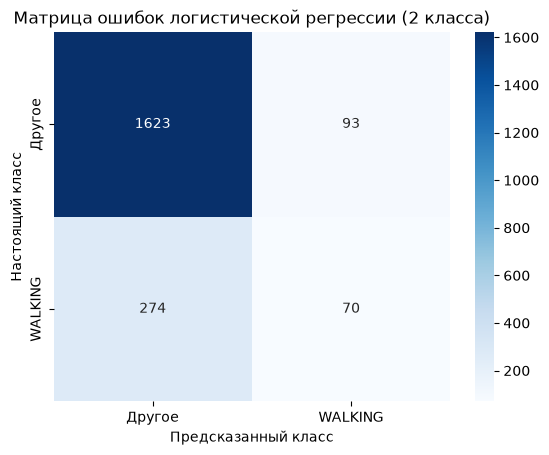

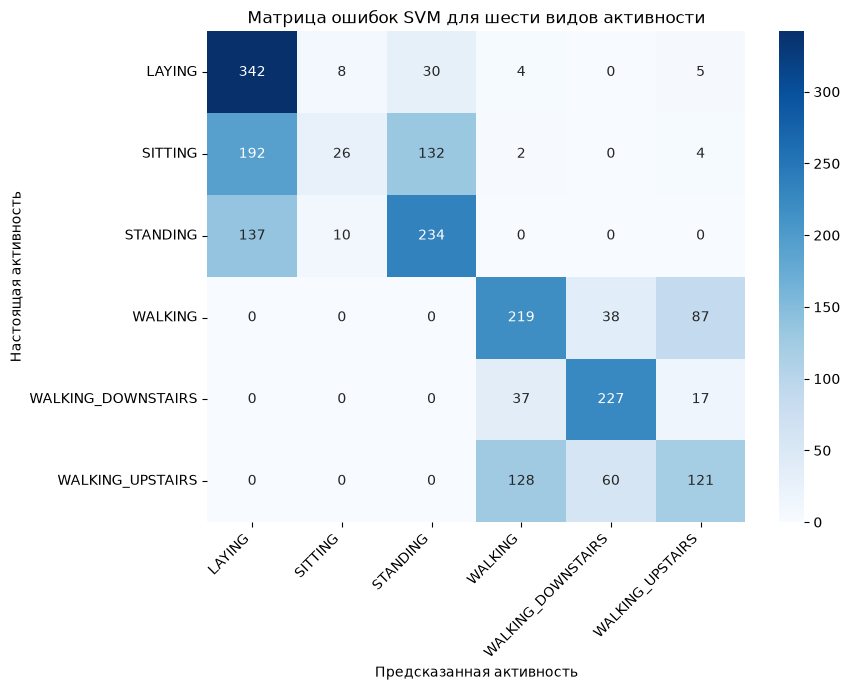

In [36]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_test_binary, logistic_predictions)
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Другое", "WALKING"],
    yticklabels=["Другое", "WALKING"],
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Настоящий класс")
plt.title("Матрица ошибок логистической регрессии (2 класса)")
plt.show()

activity_labels = sorted(y.unique())
activity_matrix = confusion_matrix(y_test, svm_predictions, labels=activity_labels)

plt.figure(figsize=(9, 7))
sns.heatmap(
    activity_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=activity_labels,
    yticklabels=activity_labels,
)
plt.xlabel("Предсказанная активность")
plt.ylabel("Настоящая активность")
plt.title("Матрица ошибок SVM для шести видов активности")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 7. Градиентный спуск (Gradient Descent)
1. Реализуйте алгоритм градиентного спуска вручную для оптимизации заданной функции стоимости.
2. Используйте простую функцию $$J(\theta) = (\theta x - y)^2$$ на подмножестве данных.

In [37]:
sample = data.sample(n=200, random_state=42)
x = sample["angle(X,gravityMean)"].to_numpy()
y_values = sample["angle(Y,gravityMean)"].to_numpy()

theta = 0.0
learning_rate = 0.1

for step in range(1000):
    predictions = theta * x
    gradient = 2 * np.mean(x * (predictions - y_values))
    theta = theta - learning_rate * gradient

cost = np.mean((theta * x - y_values) ** 2)
print("Найденное значение theta:", round(theta, 4))
print("Значение функции стоимости:", round(cost, 4))

Найденное значение theta: -0.3026
Значение функции стоимости: 0.0546


## 8. Модели машинного обучения (part 2 - poate fi omis)
3. **Случайный лес (Random Forest)**: Используйте Random Forest для обучения модели и оцените важность признаков.
4. **Бустинг и бэггинг**: Сравните производительность моделей AdaBoost и Bagging.,


## 9. Стекинг (Stacking) (poate fi omis)
1. Постройте модель стекинга, используя Random Forest, SVM и логистическую регрессию в качестве базовых моделей.
2. Используйте модель логистической регрессии в качестве мета-модели.
3. Выведите итоговую точность на тестовой выборке.


## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
